<a href="https://colab.research.google.com/github/naubergois/curso-segmentacao-colab/blob/main/notebooks/03-medir-a-mascara.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 3. Medir a máscara

A máscara pintada na foto é boa de olhar. Para usar num sistema, ela precisa virar número: que fração da imagem o objeto cobre, onde fica o centro, o quanto a caixa sobra, se duas máscaras se encostam.

Tudo isso é conta de array. A foto é de dois operários na obra, de capacete e picareta. A caixa do operário da frente leva a ferramenta, a lama e um pedaço do céu. A máscara acompanha o corpo.

In [1]:
!pip install -q ultralytics

In [2]:
import base64
import subprocess
import urllib.request
from pathlib import Path

from IPython.display import HTML, display


def baixar(url, destino):
    if not Path(destino).exists():
        urllib.request.urlretrieve(url, destino)
    print(f"{destino}: {Path(destino).stat().st_size / 1e6:.1f} MB")
    return destino


def mascaras_originais(resultado):
    """Máscaras no tamanho da foto, como array booleano (n, altura, largura).

    A rede responde numa grade menor que a imagem. Aqui a máscara é esticada
    de volta ao tamanho original, para a área bater com os pixels da foto.
    """
    import cv2
    import numpy as np

    altura, largura = resultado.orig_shape
    if resultado.masks is None or len(resultado.masks) == 0:
        return np.zeros((0, altura, largura), dtype=bool)
    saida = []
    for mascara in resultado.masks.data.cpu().numpy():
        mascara = cv2.resize(mascara, (largura, altura), interpolation=cv2.INTER_NEAREST)
        saida.append(mascara > 0.5)
    return np.stack(saida)


def mostrar_video(caminho, largura=720):
    """Converte para H.264 (o navegador não toca mp4v) e embute no notebook."""
    web = str(Path(caminho).with_suffix("")) + "_web.mp4"
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", caminho,
         "-vcodec", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", web],
        check=True,
    )
    dados = base64.b64encode(Path(web).read_bytes()).decode()
    display(HTML(f'<video width="{largura}" controls autoplay muted loop>'
                 f'<source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>'))
    return web


def baixar_para_maquina(caminho):
    try:
        from google.colab import files
        files.download(caminho)
    except ImportError:
        print(f"Fora do Colab: o arquivo está em {Path(caminho).resolve()}")

In [3]:
import numpy as np
import cv2
from ultralytics import YOLO
import matplotlib.pyplot as plt

model = YOLO("yolov8n-seg.pt")
imagem = baixar("https://raw.githubusercontent.com/naubergois/curso-segmentacao-colab/main/midia/operarios.jpg", "operarios.jpg")
resultado = model(imagem, verbose=False)[0]
mascaras = mascaras_originais(resultado)
print(f"{len(mascaras)} máscaras")

operarios.jpg: 0.6 MB


2 máscaras


## Porcentagem da foto

A média de uma máscara booleana é a fração de pixels `True`. Vezes 100, vira porcentagem.

In [4]:
for i, caixa in enumerate(resultado.boxes):
    pct = float(mascaras[i].mean()) * 100
    print(f"{model.names[int(caixa.cls)]:10s} cobre {pct:5.1f}% da foto")

person     cobre  16.1% da foto
person     cobre   2.2% da foto


## O centro

O centro da máscara é a média das posições onde ela é `True`. `np.where` devolve as linhas e as colunas. A coluna é o x.

person     centro (329, 1021)
person     centro (1064, 640)


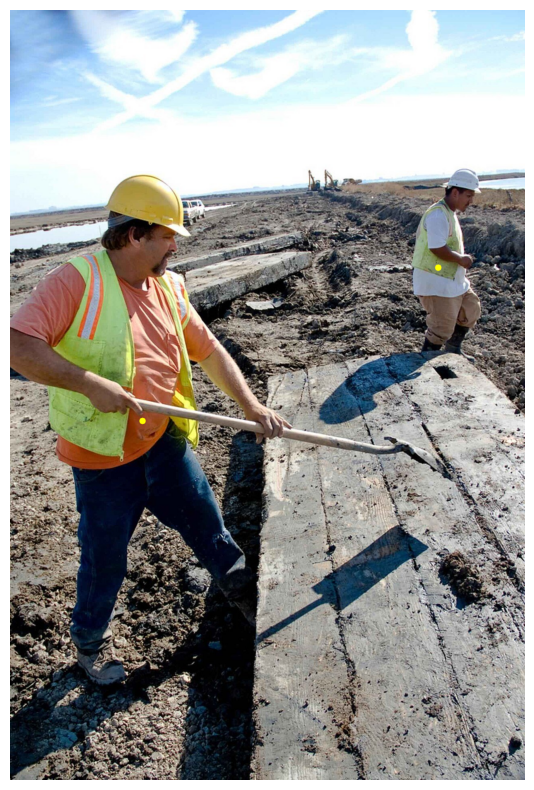

In [5]:
foto = cv2.imread(imagem)
for i, caixa in enumerate(resultado.boxes):
    ys, xs = np.where(mascaras[i])
    cx, cy = int(round(xs.mean())), int(round(ys.mean()))
    cv2.circle(foto, (cx, cy), 8, (0, 255, 255), -1)
    print(f"{model.names[int(caixa.cls)]:10s} centro ({cx}, {cy})")

plt.figure(figsize=(8, 10))
plt.imshow(foto[:, :, ::-1])
plt.axis("off")
plt.show()

## IoU entre máscara e caixa

O IoU é a interseção dividida pela união. Aqui um dos lados é a máscara e o outro é o retângulo da caixa, pintado num array do mesmo tamanho. Se o IoU fica longe de 1, a caixa inclui bastante fundo.

In [6]:
for i, caixa in enumerate(resultado.boxes):
    caixa_cheia = np.zeros(mascaras.shape[1:], dtype=bool)
    x1, y1, x2, y2 = map(int, caixa.xyxy[0].tolist())
    caixa_cheia[y1:y2, x1:x2] = True
    inter = np.logical_and(mascaras[i], caixa_cheia).sum()
    uniao = np.logical_or(mascaras[i], caixa_cheia).sum()
    print(f"{model.names[int(caixa.cls)]:10s} IoU máscara/caixa = {float(inter / uniao):.2f}")

person     IoU máscara/caixa = 0.43
person     IoU máscara/caixa = 0.60


## Quem encosta em quem

Dois objetos se tocam quando algum pixel é `True` nas duas máscaras. Na foto dos operários, a conta diz se os corpos se encontram.

In [7]:
n = len(mascaras)
for i in range(n):
    for j in range(i + 1, n):
        if np.any(mascaras[i] & mascaras[j]):
            a = model.names[int(resultado.boxes.cls[i])]
            b = model.names[int(resultado.boxes.cls[j])]
            print(f"{a} encosta em {b}")

## Exercícios

Seis perguntas sobre o que acabou de rodar. Escreva a resposta na variável `resposta` e rode a célula: a função `conferir` diz na hora se está certo. Se travar, abra **Ver solução**.

Rode antes a célula de preparação abaixo. Ela só carrega as verificações.

In [8]:
# @title Preparação dos exercícios (rode, não precisa ler)
import numpy as np

_cls = resultado.boxes.cls.int().tolist()
_xyxy = resultado.boxes.xyxy.tolist()


def _indices(nome):
    return [i for i, c in enumerate(_cls) if model.names[c] == nome]


def _i_pessoa():
    return max(_indices("person"), key=lambda i: int(mascaras[i].sum()))


def _razao_caixa(i):
    x1, y1, x2, y2 = _xyxy[i]
    return float(mascaras[i].sum()) / ((x2 - x1) * (y2 - y1))


def _centro(i):
    ys, xs = np.where(mascaras[i])
    return (int(round(xs.mean())), int(round(ys.mean())))


def _iou_caixa(i):
    caixa = np.zeros(mascaras.shape[1:], dtype=bool)
    x1, y1, x2, y2 = map(int, _xyxy[i])
    caixa[y1:y2, x1:x2] = True
    inter = np.logical_and(mascaras[i], caixa).sum()
    uniao = np.logical_or(mascaras[i], caixa).sum()
    return float(inter / uniao)


def _pares():
    n = len(mascaras)
    return sum(
        bool(np.any(mascaras[i] & mascaras[j]))
        for i in range(n) for j in range(i + 1, n)
    )


def _recorte():
    i = _i_pessoa()
    ys, xs = np.where(mascaras[i])
    return (int(ys.max() - ys.min() + 1), int(xs.max() - xs.min() + 1))


VERIFICAR = {
    1: lambda r: abs(float(r) - _razao_caixa(_i_pessoa())) < 1e-3,
    2: lambda r: abs(float(r) - float(mascaras[_i_pessoa()].mean()) * 100) < 0.1,
    3: lambda r: tuple(getattr(r, "shape", r)[:2]) == _recorte(),
    4: lambda r: all(abs(int(a) - b) <= 1 for a, b in zip(r, _centro(_i_pessoa()))),
    5: lambda r: abs(float(r) - _iou_caixa(_i_pessoa())) < 1e-3,
    6: lambda r: int(r) == _pares(),
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

### Exercício 1. Quanto da caixa é o operário

Divida a área da máscara do operário pela área da caixa dele. Use a pessoa de maior máscara. O resultado fica entre 0 e 1: é a parte da caixa que é corpo de verdade.

<details>
<summary>Ver solução</summary>

```python
i = max(
    (k for k, c in enumerate(resultado.boxes.cls) if model.names[int(c)] == "person"),
    key=lambda k: int(mascaras[k].sum()),
)
x1, y1, x2, y2 = resultado.boxes.xyxy[i].tolist()
resposta = float(mascaras[i].sum()) / ((x2 - x1) * (y2 - y1))
```

</details>

In [9]:
# Dica: Área da caixa: (x2 - x1) * (y2 - y1), com os cantos em resultado.boxes.xyxy.
resposta = None

conferir(1, resposta)

Exercício 1: ainda sem resposta.


### Exercício 2. Porcentagem da foto

Quantos por cento da foto a máscara desse operário cobre? Responda com um número de 0 a 100. Use a pessoa de maior máscara.

<details>
<summary>Ver solução</summary>

```python
i = max(
    (k for k, c in enumerate(resultado.boxes.cls) if model.names[int(c)] == "person"),
    key=lambda k: int(mascaras[k].sum()),
)
resposta = float(mascaras[i].mean()) * 100
```

</details>

In [10]:
# Dica: A média de uma máscara booleana, vezes 100, é a porcentagem.
resposta = None

conferir(2, resposta)

Exercício 2: ainda sem resposta.


### Exercício 3. Recorte do operário

Recorte a foto no retângulo justo da máscara do operário de maior máscara (o menor retângulo que ainda contém todos os pixels `True`). A resposta é o recorte.

<details>
<summary>Ver solução</summary>

```python
i = max(
    (k for k, c in enumerate(resultado.boxes.cls) if model.names[int(c)] == "person"),
    key=lambda k: int(mascaras[k].sum()),
)
img = cv2.imread(imagem)
ys, xs = np.where(mascaras[i])
resposta = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

plt.imshow(resposta[:, :, ::-1])
plt.axis("off")
plt.show()
```

</details>

In [11]:
# Dica: np.where devolve as linhas e as colunas. O recorte é img[y_min:y_max+1, x_min:x_max+1].
resposta = None

conferir(3, resposta)

Exercício 3: ainda sem resposta.


### Exercício 4. Centro do operário

Ache o centro do operário de maior máscara. Responda com `(x, y)` em pixels, x na horizontal.

<details>
<summary>Ver solução</summary>

```python
i = max(
    (k for k, c in enumerate(resultado.boxes.cls) if model.names[int(c)] == "person"),
    key=lambda k: int(mascaras[k].sum()),
)
ys, xs = np.where(mascaras[i])
resposta = (int(round(xs.mean())), int(round(ys.mean())))
```

</details>

In [12]:
# Dica: np.where(mascara) devolve (linhas, colunas). A média das colunas é o x.
resposta = None

conferir(4, resposta)

Exercício 4: ainda sem resposta.


### Exercício 5. IoU com a caixa

Calcule o IoU entre a máscara do operário de maior máscara e o retângulo da caixa dele. IoU é a interseção dividida pela união.

<details>
<summary>Ver solução</summary>

```python
i = max(
    (k for k, c in enumerate(resultado.boxes.cls) if model.names[int(c)] == "person"),
    key=lambda k: int(mascaras[k].sum()),
)
caixa = np.zeros(mascaras.shape[1:], dtype=bool)
x1, y1, x2, y2 = map(int, resultado.boxes.xyxy[i].tolist())
caixa[y1:y2, x1:x2] = True
inter = np.logical_and(mascaras[i], caixa).sum()
uniao = np.logical_or(mascaras[i], caixa).sum()
resposta = float(inter / uniao)
```

</details>

In [13]:
# Dica: Pinte um array booleano só dentro da caixa e compare com a máscara usando & e |.
resposta = None

conferir(5, resposta)

Exercício 5: ainda sem resposta.


### Exercício 6. Máscaras que se tocam

Quantos pares de máscaras têm pelo menos um pixel em comum?

<details>
<summary>Ver solução</summary>

```python
pares = 0
n = len(mascaras)
for i in range(n):
    for j in range(i + 1, n):
        if np.any(mascaras[i] & mascaras[j]):
            pares += 1
resposta = pares
```

</details>

In [14]:
# Dica: Para cada par i < j, np.any(mascaras[i] & mascaras[j]) diz se elas se encostam.
resposta = None

conferir(6, resposta)

Exercício 6: ainda sem resposta.


In [15]:
placar()

0 de 6 exercícios certos.


## O que fica

Área, centro, IoU e sobreposição saem da mesma grade de verdadeiro ou falso. Isso ainda não desenha uma classe sua: o modelo só conhece as 80 classes do COCO. Uma classe nova pede fotos com o contorno marcado.